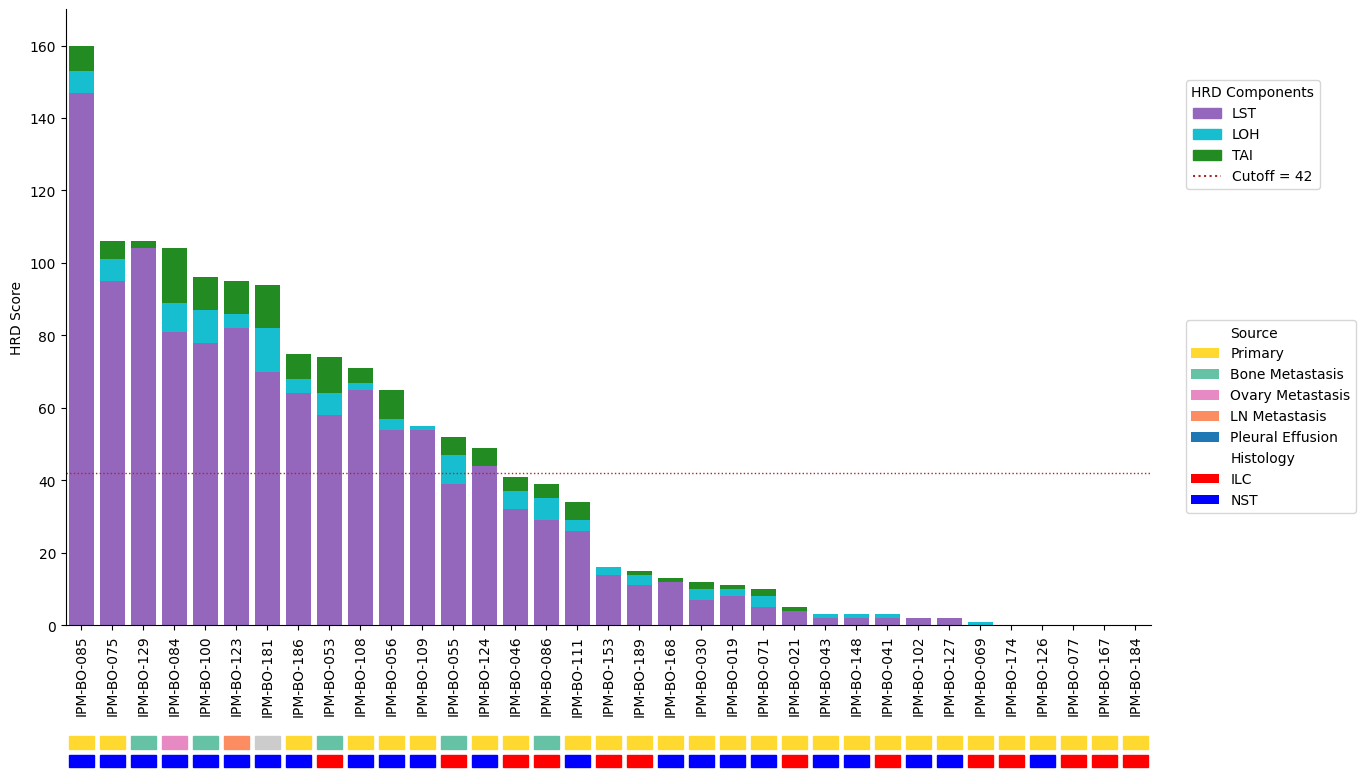

Plot saved at: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Plot/IPM_ALL_HRD_Stacked_Bar_Plot_Annotated_FullY.png


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Load the data
df = pd.read_csv("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/IPM-BO-HRD.csv")

# Sort samples by HRD total score for better visual consistency
df = df.sort_values("Total", ascending=False).reset_index(drop=True)

# Create color maps for Source and Histology
source_colors = {
    "Bone Metastasis": (102/255, 194/255, 165/255),
    "LN Metastasis": (252/255, 141/255, 98/255),
    "Liver Metastasis": (141/255, 160/255, 203/255),
    "Ovary Metastasis": (231/255, 138/255, 195/255),
    "Pleural Effusion": (166/255, 216/255, 84/255),
    "Primary": (255/255, 217/255, 47/255),
}

histology_colors = {"ILC": "#FF0000", "NST": "#0000FF"}

# Create the figure and axis
fig, ax = plt.subplots(figsize=(14, 8))

# Define unique, unused colors for LST and LOH
color_lst = "#9467bd"   # Purple
color_loh = "#17becf"   # Orange
color_tai = "#228B22"   # Forest Green

# Plot stacked bars
ax.bar(df["Sample"], df["LST"], color=color_lst, label='LST')
ax.bar(df["Sample"], df["LOH"], bottom=df["LST"], color=color_loh, label='LOH')
ax.bar(df["Sample"], df["TAI"], bottom=df["LST"] + df["LOH"], color=color_tai, label='TAI')

# Set Y-axis limit
ax.set_ylim(0, df["Total"].max() + 10)

# Draw cutoff line at HRD = 42
ax.axhline(y=42, color='brown', linestyle='dotted', linewidth=1)

# Set X-axis labels
ax.set_xticks(range(len(df["Sample"])))
ax.set_xticklabels(df["Sample"], rotation=90, ha='center')
ax.set_xlim(-0.5, len(df["Sample"]) - 0.5)

# Add annotation bars *just below* the sample labels using Axes coordinates
bar_width = 0.8
bar_height = 0.02  # small height in axes fraction
for i, sample in enumerate(df["Sample"]):
    source = df.loc[i, "Source"]
    hist = df.loc[i, "Histology"]

    x = i - bar_width / 2

    ax.add_patch(plt.Rectangle(
        (x, -0.20), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=source_colors.get(source, "#cccccc"),
        clip_on=False
    ))

    ax.add_patch(plt.Rectangle(
        (x, -0.23), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=histology_colors.get(hist, "#888888"),
        clip_on=False
    ))

# Remove top and right spines (clean plot frame)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

# Axis label
ax.set_ylabel("HRD Score")

# --- Build grouped legend ---
legend_elements = []
legend_group_titles = {
    "Source": df["Source"].dropna().unique(),
    "Histology": ["ILC", "NST"]
}
for group_name, items in legend_group_titles.items():
    legend_elements.append(Patch(facecolor='white', edgecolor='white', label=group_name))
    for item in items:
        color = source_colors.get(item) if group_name == "Source" else histology_colors.get(item, "#cccccc")
        legend_elements.append(Patch(facecolor=color, label=item))

# Custom legend for main HRD components and cutoff line
hrd_legend = [
    Patch(color=color_lst, label="LST"),
    Patch(color=color_loh, label="LOH"),
    Patch(color=color_tai, label="TAI"),
    Line2D([0], [0], color='brown', linestyle='dotted', linewidth=1.5, label="Cutoff = 42")
]

# Place legends using fig.legend to avoid overwriting
fig.legend(handles=hrd_legend, loc='upper left', bbox_to_anchor=(0.92, 0.8), title="HRD Components")
fig.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(0.92, 0.5), frameon=True, title_fontsize=12)

# Save the final plot
save_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Plot"
os.makedirs(save_path, exist_ok=True)
save_file = os.path.join(save_path, "IPM_ALL_HRD_Stacked_Bar_Plot_Annotated_FullY.png")
plt.savefig(save_file, dpi=300, bbox_inches='tight')
plt.show()

print(f"Plot saved at: {save_file}")

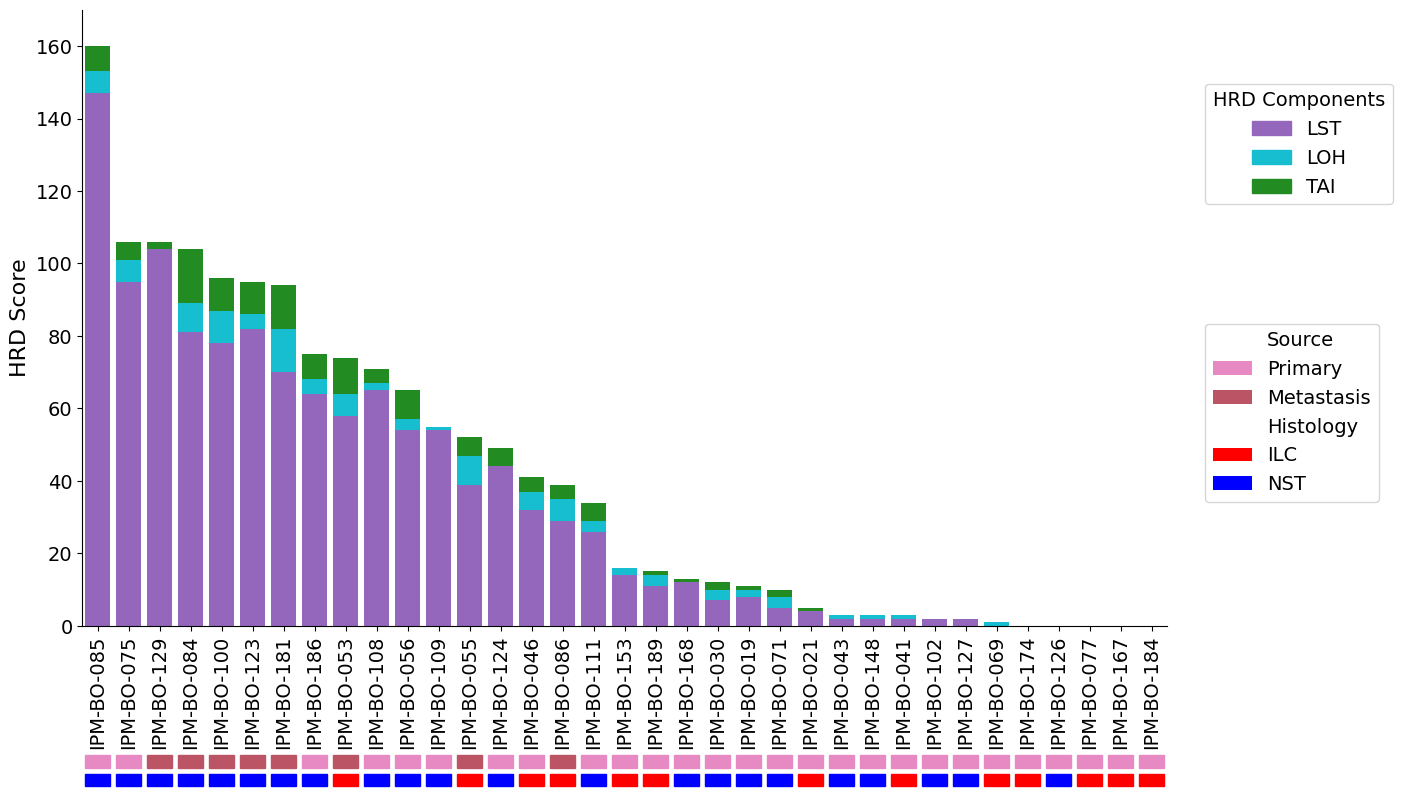

Plot saved at: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Plot/IPM_ALL_HRD_Stacked_Bar_Plot_Annotated_FullY.png
Plot saved at: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Plot/IPM_ALL_HRD_Stacked_Bar_Plot_Annotated_FullY.pdf


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# =============================
# Global font size and style
# =============================
plt.rcParams.update({
    "font.family": "DejaVu Sans",   # or 'Arial', 'Times New Roman'
    "axes.labelsize": 16,         # Axis label font
    "xtick.labelsize": 14,        # X-tick font
    "ytick.labelsize": 14,        # Y-tick font
    "legend.fontsize": 14,        # Legend text font
    "legend.title_fontsize": 14   # Legend title font
})

# Load the data
df = pd.read_csv("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/IPM-BO-HRD.csv")

# Sort samples by HRD total score for better visual consistency
df = df.sort_values("Total", ascending=False).reset_index(drop=True)

# Create color maps for Source and Histology
source_colors = {
    "Metastasis": "#BB5566",
    "Primary": "#E78AC3"
}

histology_colors = {"ILC": "#FF0000", "NST": "#0000FF"}

# Create the figure and axis
fig, ax = plt.subplots(figsize=(14, 8))

# Define unique, unused colors for LST and LOH
color_lst = "#9467bd"   # Purple
color_loh = "#17becf"   # Orange
color_tai = "#228B22"   # Forest Green

# Plot stacked bars
ax.bar(df["Sample"], df["LST"], color=color_lst, label='LST')
ax.bar(df["Sample"], df["LOH"], bottom=df["LST"], color=color_loh, label='LOH')
ax.bar(df["Sample"], df["TAI"], bottom=df["LST"] + df["LOH"], color=color_tai, label='TAI')

# Set Y-axis limit
ax.set_ylim(0, df["Total"].max() + 10)

# Draw cutoff line at HRD = 42
#ax.axhline(y=42, color='brown', linestyle='dotted', linewidth=1)

# Set X-axis labels
ax.set_xticks(range(len(df["Sample"])))
ax.set_xticklabels(df["Sample"], rotation=90, ha='center')
ax.set_xlim(-0.5, len(df["Sample"]) - 0.5)
ax.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True)

# Add annotation bars *just below* the sample labels using Axes coordinates
bar_width = 0.8
bar_height = 0.02  # small height in axes fraction
for i, sample in enumerate(df["Sample"]):
    source = df.loc[i, "Source"]
    hist = df.loc[i, "Histology"]

    x = i - bar_width / 2

    ax.add_patch(plt.Rectangle(
        (x, -0.23), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=source_colors.get(source, "#cccccc"),
        clip_on=False
    ))

    ax.add_patch(plt.Rectangle(
        (x, -0.26), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=histology_colors.get(hist, "#888888"),
        clip_on=False
    ))

# Remove top and right spines (clean plot frame)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

# Axis label
ax.set_ylabel("HRD Score")

# --- Build grouped legend ---
legend_elements = []
legend_group_titles = {
    "Source": df["Source"].dropna().unique(),
    "Histology": ["ILC", "NST"]
}
for group_name, items in legend_group_titles.items():
    legend_elements.append(Patch(facecolor='white', edgecolor='white', label=group_name))
    for item in items:
        color = source_colors.get(item) if group_name == "Source" else histology_colors.get(item, "#cccccc")
        legend_elements.append(Patch(facecolor=color, label=item))

# Custom legend for main HRD components and cutoff line
hrd_legend = [
    Patch(color=color_lst, label="LST"),
    Patch(color=color_loh, label="LOH"),
    Patch(color=color_tai, label="TAI"),
    #Line2D([0], [0], color='brown', linestyle='dotted', linewidth=1.5, label="Cutoff = 42")
]

# Place legends using fig.legend to avoid overwriting
fig.legend(handles=hrd_legend, loc='upper left', bbox_to_anchor=(0.92, 0.8), title="HRD Components")
fig.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(0.92, 0.5), frameon=True, title_fontsize=14)

# Save the final plot
save_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Plot"
os.makedirs(save_path, exist_ok=True)

png_file = os.path.join(save_path, "IPM_ALL_HRD_Stacked_Bar_Plot_Annotated_FullY.png")
pdf_file = os.path.join(save_path, "IPM_ALL_HRD_Stacked_Bar_Plot_Annotated_FullY.pdf")

plt.savefig(png_file, dpi=300, bbox_inches='tight')
plt.savefig(pdf_file, bbox_inches='tight')

plt.show()

print(f"Plot saved at: {png_file}")
print(f"Plot saved at: {pdf_file}")

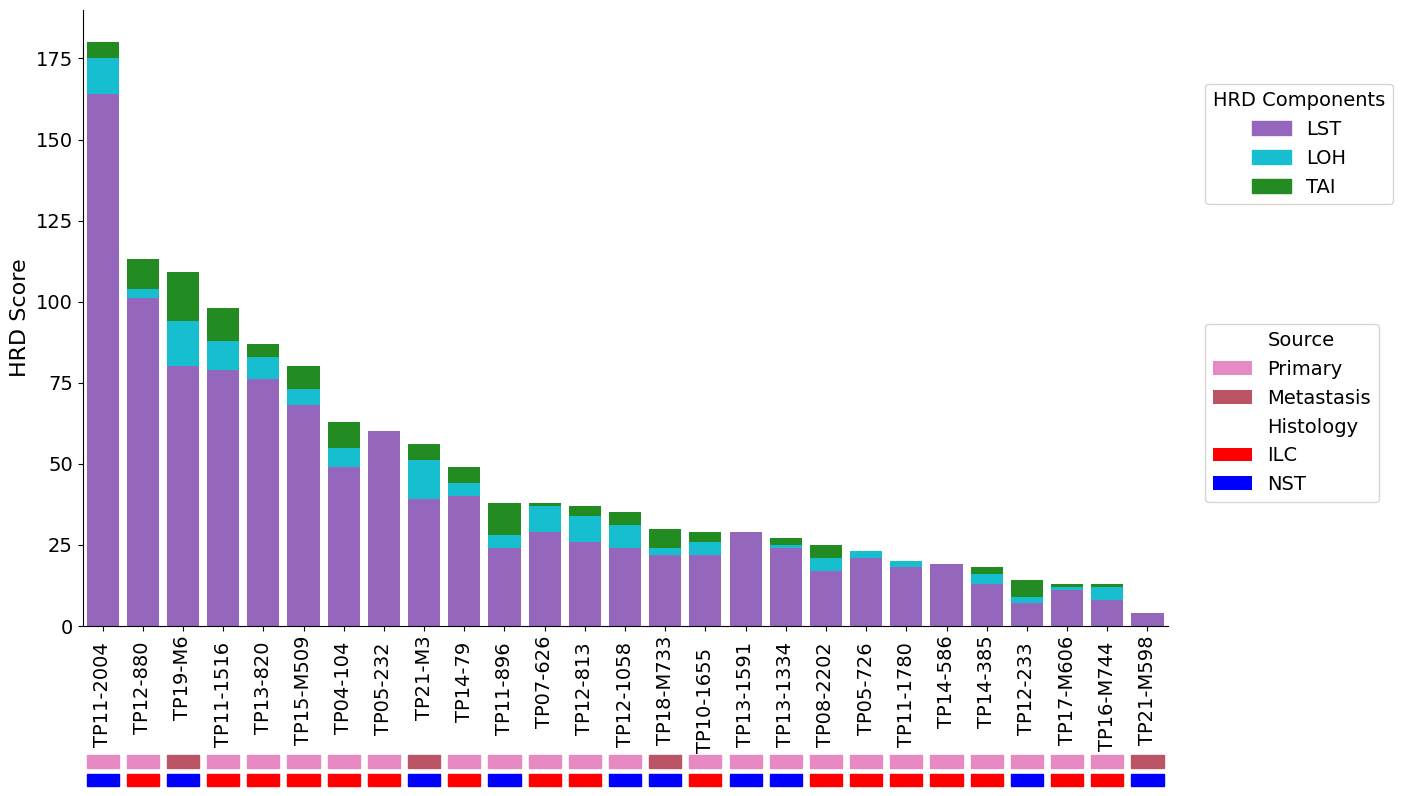

Plot saved at: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Plot/Tumor_ALL_HRD_Stacked_Bar_Plot_Annotated_FullY.png
Plot saved at: /ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Plot/Tumor_ALL_HRD_Stacked_Bar_Plot_Annotated_FullY.pdf


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# =============================
# Global font size and style
# =============================
plt.rcParams.update({
    "font.family": "DejaVu Sans",   # or 'Arial', 'Times New Roman'
    "axes.labelsize": 16,         # Axis label font
    "xtick.labelsize": 14,        # X-tick font
    "ytick.labelsize": 14,        # Y-tick font
    "legend.fontsize": 14,        # Legend text font
    "legend.title_fontsize": 14   # Legend title font
})

# --- Load the new dataset ---
df = pd.read_csv("/ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Tumor_HRD.csv")
df = df.sort_values("Total", ascending=False).reset_index(drop=True)

# Create color maps for Source and Histology
source_colors = {
    "Metastasis": "#BB5566",
    "Primary": "#E78AC3"
}

histology_colors = {"ILC": "#FF0000", "NST": "#0000FF"}

# Create the figure and axis
fig, ax = plt.subplots(figsize=(14, 8))

# Define unique, unused colors for LST and LOH
color_lst = "#9467bd"   # Purple
color_loh = "#17becf"   # Orange
color_tai = "#228B22"   # Forest Green

# Plot stacked bars
ax.bar(df["Sample"], df["LST"], color=color_lst, label='LST')
ax.bar(df["Sample"], df["LOH"], bottom=df["LST"], color=color_loh, label='LOH')
ax.bar(df["Sample"], df["TAI"], bottom=df["LST"] + df["LOH"], color=color_tai, label='TAI')

# Set Y-axis limit
ax.set_ylim(0, df["Total"].max() + 10)

# Draw cutoff line at HRD = 42
# ax.axhline(y=42, color='brown', linestyle='dotted', linewidth=1)

# Set X-axis labels
ax.set_xticks(range(len(df["Sample"])))
ax.set_xticklabels(df["Sample"], rotation=90, ha='center')
ax.set_xlim(-0.5, len(df["Sample"]) - 0.5)
ax.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True)

# Add annotation bars *just below* the sample labels using Axes coordinates
bar_width = 0.8
bar_height = 0.02  # small height in axes fraction
for i, sample in enumerate(df["Sample"]):
    source = df.loc[i, "Source"]
    hist = df.loc[i, "Histology"]

    x = i - bar_width / 2

    ax.add_patch(plt.Rectangle(
        (x, -0.23), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=source_colors.get(source, "#cccccc"),
        clip_on=False
    ))

    ax.add_patch(plt.Rectangle(
        (x, -0.26), bar_width, bar_height,
        transform=ax.get_xaxis_transform(),
        color=histology_colors.get(hist, "#888888"),
        clip_on=False
    ))

# Remove top and right spines (clean plot frame)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

# Axis label
ax.set_ylabel("HRD Score")

# --- Build grouped legend ---
legend_elements = []
legend_group_titles = {
    "Source": df["Source"].dropna().unique(),
    "Histology": ["ILC", "NST"]
}
for group_name, items in legend_group_titles.items():
    legend_elements.append(Patch(facecolor='white', edgecolor='white', label=group_name))
    for item in items:
        color = source_colors.get(item) if group_name == "Source" else histology_colors.get(item, "#cccccc")
        legend_elements.append(Patch(facecolor=color, label=item))

# Custom legend for main HRD components and cutoff line
hrd_legend = [
    Patch(color=color_lst, label="LST"),
    Patch(color=color_loh, label="LOH"),
    Patch(color=color_tai, label="TAI"),
    # Line2D([0], [0], color='brown', linestyle='dotted', linewidth=1.5, label="Cutoff = 42")
]

# Place legends using fig.legend to avoid overwriting
fig.legend(handles=hrd_legend, loc='upper left', bbox_to_anchor=(0.92, 0.8), title="HRD Components")
fig.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(0.92, 0.5), frameon=True, title_fontsize=14)

# --- Save plot ---
save_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/HRD/Plot"
os.makedirs(save_path, exist_ok=True)
png_file = os.path.join(save_path, "Tumor_ALL_HRD_Stacked_Bar_Plot_Annotated_FullY.png")
pdf_file = os.path.join(save_path, "Tumor_ALL_HRD_Stacked_Bar_Plot_Annotated_FullY.pdf")

plt.savefig(png_file, dpi=300, bbox_inches='tight')
plt.savefig(pdf_file, bbox_inches='tight') 

plt.show()

print(f"Plot saved at: {png_file}")
print(f"Plot saved at: {pdf_file}")
